# Figure 5: Multi-MNIST

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.gridspec as gridspec
from string import ascii_lowercase as _abc
import matplotlib.pyplot as plt
import torch 
import string
from matplotlib import ticker


In [2]:
def add_panel_label(ax, label, x=0.82, y=0.98):
    ax.text(x, y, label, transform=ax.transAxes, ha="left", va="top",
            fontsize=12, fontweight="bold",
            path_effects=[pe.Stroke(linewidth=1.6, foreground="white"), pe.Normal()],
            zorder=10)

def hide_axes(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_aspect("equal")

def annotate_diagonal(ax, M, fmt="{:.2f}", cmap=None, norm=None, fs=8, maxn=12):
    n = min(M.shape)
    if n > maxn:  # avoid clutter on large matrices
        return
    # simple luminance for auto-contrast
    for k in range(n):
        v = M[k, k]
        r, g, b, _ = (cmap(norm(v)) if (cmap and norm) else (0,0,0,1))
        lum = 0.2126*r + 0.7152*g + 0.0722*b
        color = "black" if lum > 0.5 else "white"
        halo  = "white" if color == "black" else "black"
        ax.text(k, k, fmt.format(v), ha="center", va="center",
                fontsize=fs, fontweight="semibold", color=color,
                path_effects=[pe.Stroke(linewidth=1.0, foreground=halo), pe.Normal()],
                clip_on=True)


## Losses

### Baseline Multi-MNIST

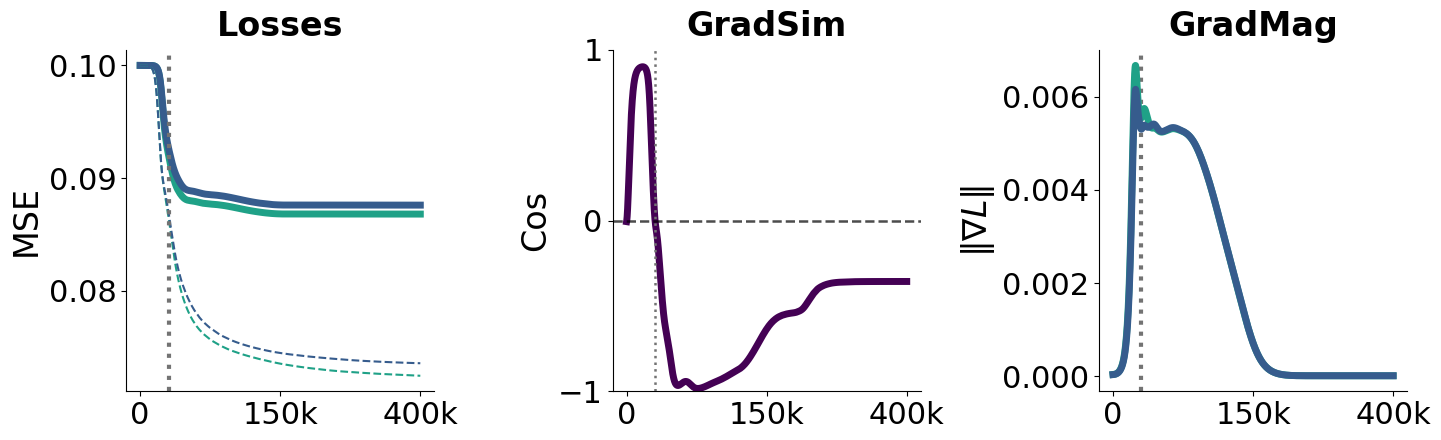

In [ ]:
ALI_linear = np.load("")  #root of multimnist_seed33_shift4_ali_uniform_h20gpujunenlin_multimnist_b50000_h20_s400000
ALI_nonlinear = np.load("")  #root of multimnist_seed33_shift4_ali_uniform_h20gpujunennonlin_multimnist_b50000_h20_s400000
ALI_nonlinear_Loss1 = ALI_nonlinear["losses1"]
ALI_nonlinear_Loss2 = ALI_nonlinear["losses2"]
loss1 = ALI_linear["losses1"]
loss2 = ALI_linear["losses2"]
cossim = ALI_linear["cossim"]
gradmag1 = ALI_linear["gradmag1"]
gradmag2 = ALI_linear["gradmag2"]

steps = np.arange(400000)

cmap = plt.get_cmap("viridis", 8)
task1color = cmap(4)
task2color = cmap(2)
shared_color = cmap(0)

labelsize = 24
axessize = 22
legendsize = 18
lw = 5

fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.5), sharex=True)

# Losses
ax = axs[0]
ax.plot(steps, loss1[:len(steps)], color=task1color, lw=lw, label="Task 1")
ax.plot(steps, loss2[:len(steps)], color=task2color, lw=lw, label="Task 2")
ax.plot(steps, ALI_nonlinear_Loss1[:len(steps)], "--", color=task1color, markersize=6, label="Task 1 Nonlinear")
ax.plot(steps, ALI_nonlinear_Loss2[:len(steps)],"--", color=task2color, markersize=6, label="Task 2 Nonlinear")
ax.set_title("Losses", fontsize=labelsize, fontweight="bold", pad=10)
ax.set_ylabel("MSE", fontsize=labelsize)
#ax.set_xlabel("Training step", fontsize=labelsize)
ax.tick_params(axis="both", labelsize=axessize)
#ax.legend(frameon=False, fontsize=legendsize)

# GradSim
# First positive-to-negative GradSim crossing
crossings = np.where((cossim[:-1] > 0) & (cossim[1:] <= 0))[0]

if len(crossings):
    zero_idx = crossings[0] + 1

    # Percentage decrease relative to the initial linear loss
    learned_task1 = 100 * (
    (loss1[0] - loss1[zero_idx]) /
    (loss1[0] - loss1[-1])
     )

    learned_task2 = 100 * (
    (loss2[0] - loss2[zero_idx]) /
    (loss2[0] - loss2[-1])
    )
else:
    zero_idx = None
# GradSim
ax = axs[1]
ax.plot(steps, cossim[:len(steps)], color=shared_color, lw=lw)
ax.set_ylim(-1, 1)
ax.set_yticks([-1, 0, 1])
# Zero-gradient-similarity reference
ax.axhline(0, color="black", linestyle="--", lw=1.8, alpha=0.7)

if zero_idx is not None:
    crossing_step = steps[zero_idx]

    ax.axvline(
        crossing_step,
        color="0.45",
        linestyle=":",
        lw=1.8,
    )
    

    axs[0].axvline(
        crossing_step,
        color="0.45",
        linestyle=":",
        lw=3,
    )
    
    axs[2].axvline(
        crossing_step,
        color="0.45",
        linestyle=":",
        lw=3,
    )
    '''
    annotation = (
        f"Step {crossing_step:,}\n"
        f"Task 1 loss decrease: {learned_task1:.1f}%\n"
        f"Task 2 loss decrease: {learned_task2:.1f}%"
    )
    
    ax.annotate(
        annotation,
        xy=(crossing_step, 0),
        xytext=(12, 18),
        textcoords="offset points",
        fontsize=legendsize,
        ha="left",
        va="bottom",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="0.7",
            alpha=0.9,
        ),
    )
'''
ax.set_title("GradSim", fontsize=labelsize, fontweight="bold", pad=10)
ax.set_ylabel("Cos", fontsize=labelsize)
#ax.set_xlabel("Epochs", fontsize=labelsize)
ax.tick_params(axis="both", labelsize=axessize)

# GradMag
ax = axs[2]
ax.plot(steps, gradmag1[:len(steps)], color=task1color, lw=lw, label="Task 1")
ax.plot(steps, gradmag2[:len(steps)], color=task2color, lw=lw, label="Task 2")
ax.set_title("GradMag", fontsize=labelsize, fontweight="bold", pad=10)
ax.set_ylabel(r"$\|\nabla L\|$", fontsize=labelsize)
#ax.set_xlabel("Training step", fontsize=labelsize)
ax.tick_params(axis="both", labelsize=axessize)
#ax.legend(frameon=False, fontsize=legendsize)

for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xticks([0, 200000, 400000])
    ax.set_xticklabels(["0", "150k", "400k"])

fig.tight_layout()

### Permuted Multi-MNIST

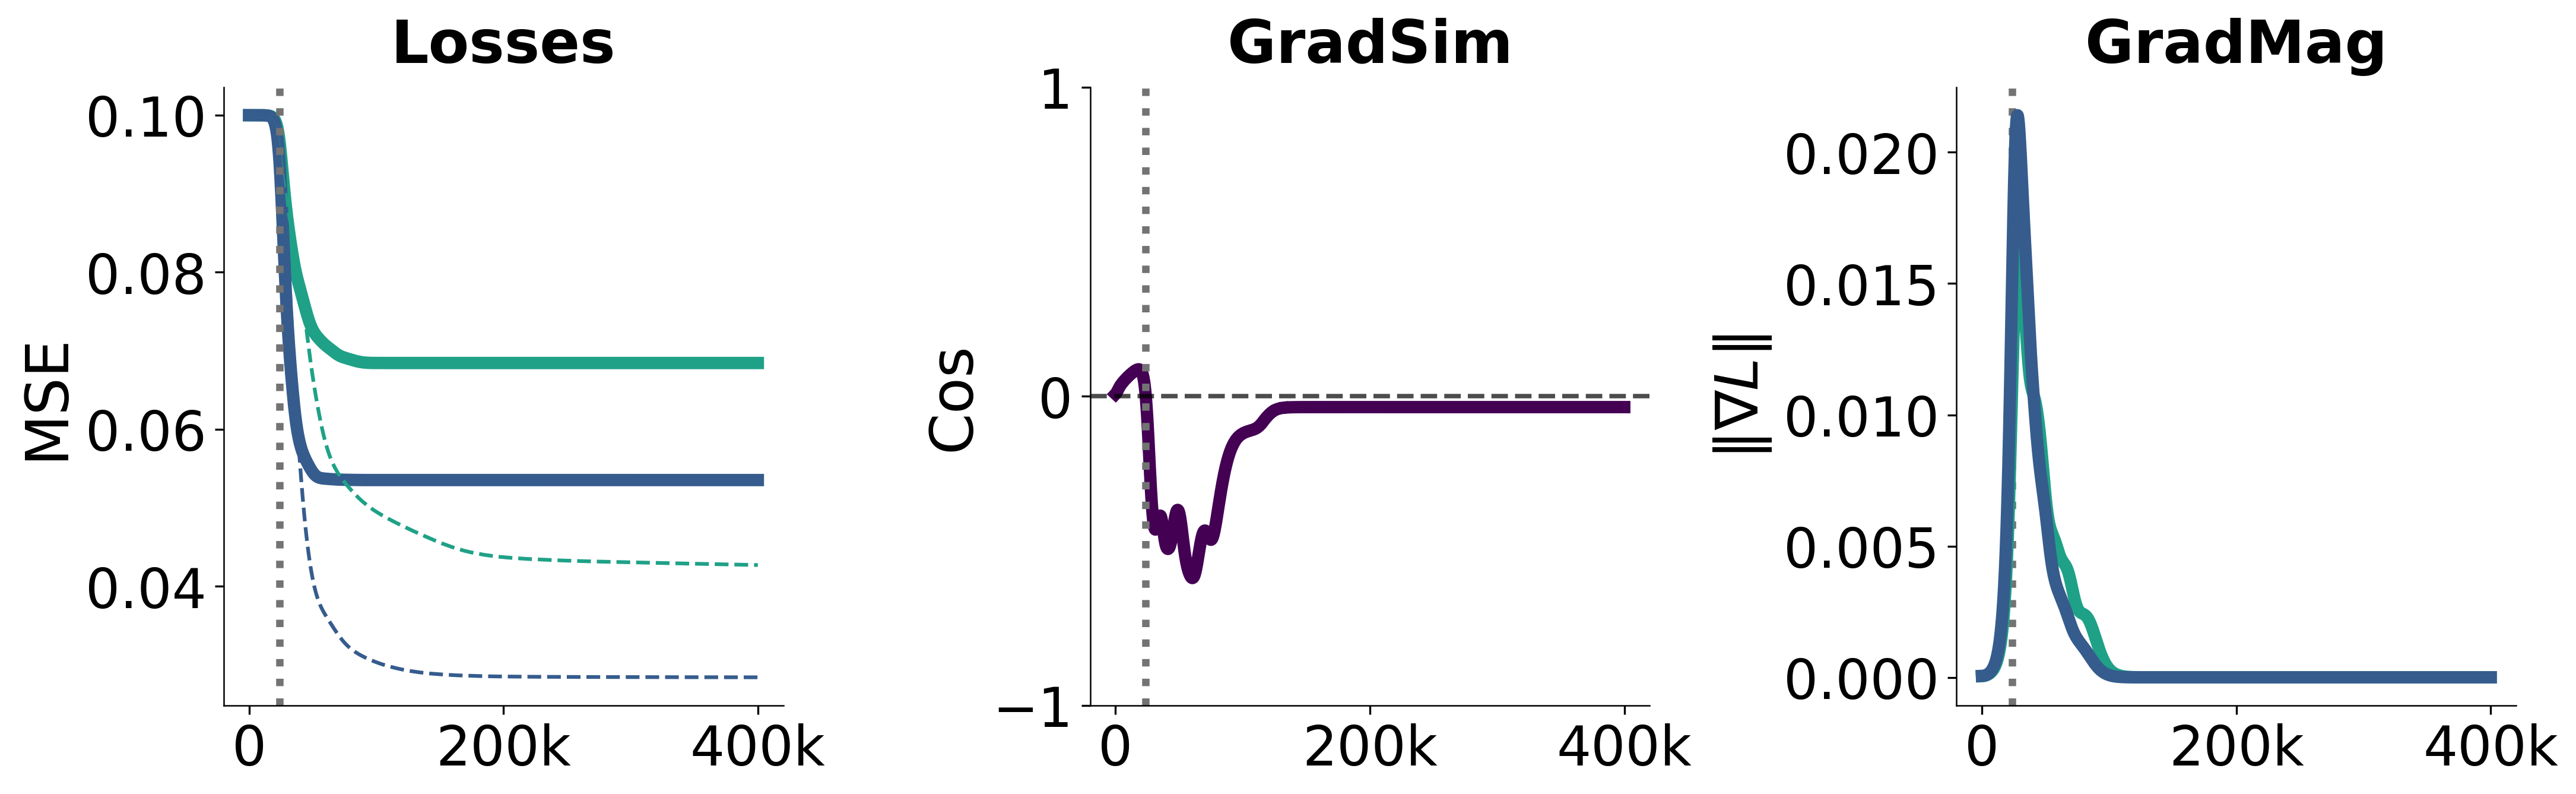

In [ ]:
Perm_linear=np.load("")#root for multimnist_seed33_shift4_permuted_uniform_h20gpujunenlin_multimnist_b50000_h20_s400000.npz
Perm_nonlinear=np.load("")#root for multimnist_seed33_shift4_permuted_uniform_h20gpujunennonlin_multimnist_b50000_h20_s400000.npz
loss1=Perm_linear["losses1"]
loss2=Perm_linear["losses2"]
cossim = Perm_linear["cossim"]
gradmag1 = Perm_linear["gradmag1"]
gradmag2 = Perm_linear["gradmag2"]

steps = np.arange(400000)

cmap = plt.get_cmap("viridis", 8)
task1color = cmap(4)
task2color = cmap(2)
shared_color = cmap(0)

labelsize = 24
axessize = 22
legendsize = 18
lw = 5

fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.5), sharex=True)

# Losses
ax = axs[0]
ax.plot(steps, loss1[:len(steps)], color=task1color, lw=lw, label="Task 1")
ax.plot(steps, loss2[:len(steps)], color=task2color, lw=lw, label="Task 2")
ax.plot(steps[:len(Perm_nonlinear["losses1"])], Perm_nonlinear["losses1"][:len(steps)], "--", color=task1color, markersize=6, label="Task 1 Nonlinear")
ax.plot(steps[:len(Perm_nonlinear["losses2"])], Perm_nonlinear["losses2"][:len(steps)], "--", color=task2color, markersize=6, label="Task 2 Nonlinear")
ax.set_title("Losses", fontsize=labelsize, fontweight="bold", pad=10)
ax.set_ylabel("MSE", fontsize=labelsize)
#ax.set_xlabel("Epochs", fontsize=labelsize)
ax.tick_params(axis="both", labelsize=axessize)
#ax.legend(frameon=False, fontsize=legendsize)

# GradSim
# First positive-to-negative GradSim crossing
crossings = np.where((cossim[:-1] > 0) & (cossim[1:] <= 0))[0]

if len(crossings):
    zero_idx = crossings[0] + 1

    # Percentage decrease relative to the initial linear loss
    learned_task1 = 100 * (
    (loss1[0] - loss1[zero_idx]) /
    (loss1[0] - loss1[-1])
     )

    learned_task2 = 100 * (
    (loss2[0] - loss2[zero_idx]) /
    (loss2[0] - loss2[-1])
    )
else:
    zero_idx = None
# GradSim
ax = axs[1]
ax.plot(steps[:len(cossim)], cossim[:len(steps)], color=shared_color, lw=lw)
ax.set_ylim(-1, 1)
ax.set_yticks([-1, 0, 1]) 
# Zero-gradient-similarity reference
ax.axhline(0, color="black", linestyle="--", lw=1.8, alpha=0.7)

if zero_idx is not None:
    crossing_step = steps[zero_idx]

    ax.axvline(
        crossing_step,
        color="0.45",
        linestyle=":",
        lw=3,
    )

    axs[0].axvline(
        crossing_step,
        color="0.45",
        linestyle=":",
        lw=3,
    )
    
    axs[2].axvline(
        crossing_step,
        color="0.45",
        linestyle=":",
        lw=3,
    )

ax.set_title("GradSim", fontsize=labelsize, fontweight="bold", pad=10)
ax.set_ylabel("Cos", fontsize=labelsize)
#ax.set_xlabel("Epochs", fontsize=labelsize)
ax.tick_params(axis="both", labelsize=axessize)

# GradMag
ax = axs[2]
ax.plot(steps[:len(gradmag1)], gradmag1[:len(steps)], color=task1color, lw=lw, label="Task 1")
ax.plot(steps[:len(gradmag2)], gradmag2[:len(steps)], color=task2color, lw=lw, label="Task 2")
ax.set_title("GradMag", fontsize=labelsize, fontweight="bold", pad=10)
ax.set_ylabel(r"$\|\nabla L\|$", fontsize=labelsize)
#ax.set_xlabel("Epochs", fontsize=labelsize)
ax.tick_params(axis="both", labelsize=axessize)
#ax.legend(frameon=False, fontsize=legendsize)

for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xticks([0, 200000, 400000])
    ax.set_xticklabels(["0", "200k", "400k"])

fig.tight_layout()


## Representations

### Baseline Multi-MNIST

In [ ]:
qq=np.loadtxt("") # root QQ_NN_BAS50K200Kep.txt
Sigma_1o=np.loadtxt("") # root Sigma_1o_BAS50K200Kep.txt
Sigma_2o=np.loadtxt("") # root Sigma_2o_BAS50K200Kep.txt

In [137]:
WSWS=qq[:1296,:1296]
W1W1=qq[1296:1296+10, 1296:1296+10]
W2W2=qq[1296+10: 1296+20, 1296+10: 1296+20]
STL=False
Task1=False
if STL==False:
  U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
  U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
elif Task1:
  U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
  Sigma_2o=Sigma_1o
  U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
else:
  U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
  Sigma_1o=Sigma_2o
  U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
# assume U1,S1,Vt1; U2,S2,Vt2; U_xi,S_xi,Vt_xi are computed
XI=np.concatenate((Sigma_1o, Sigma_2o), axis=0)
U_xi,S_xi,Vt_xi=np.linalg.svd(XI,full_matrices=True)
m1 = U1.shape[0]
m2 = U2.shape[0]
r  = S_xi.size

# build original energy‐matrices
M1 = U1  @ np.diag(S1)  @ U1.T
M2 = U2  @ np.diag(S2)  @ U2.T
Mxi1= (U_xi@ np.diag(S_xi)@U_xi.T)[:m1, :m1]
Mxi2=(U_xi@ np.diag(S_xi)@U_xi.T)[m1:m1+m2, m1:m1+m2]
Mxi=(U_xi@ np.diag(S_xi)@U_xi.T)
# split pooled U_xi
U1_xi = U_xi[:m1, :m1]   # (m1 x r)
U2_xi = U_xi[m1:, m1:]   # (m2 x r)
# project into shared r‐dim space
M1p = U1_xi.T @ M1  @ U1_xi  # (r x r)
M2p = U2_xi.T @ M2  @ U2_xi  # (r x r)
Mxp = S_xi**2    # = diag(S_xi^2)


S1_mat = np.diag(S1)
S2_mat = np.diag(S2)
Sxi_mat = np.diag(S_xi)

# Third row: VSV^T
V1SV1 = V1.T @ np.diag(S1) @ V1
V2SV2 = V2.T @ np.diag(S2) @ V2
VxiSVxi = Vt_xi.T[:, :len(S_xi)] @ np.diag(S_xi) @ Vt_xi[:len(S_xi),:]

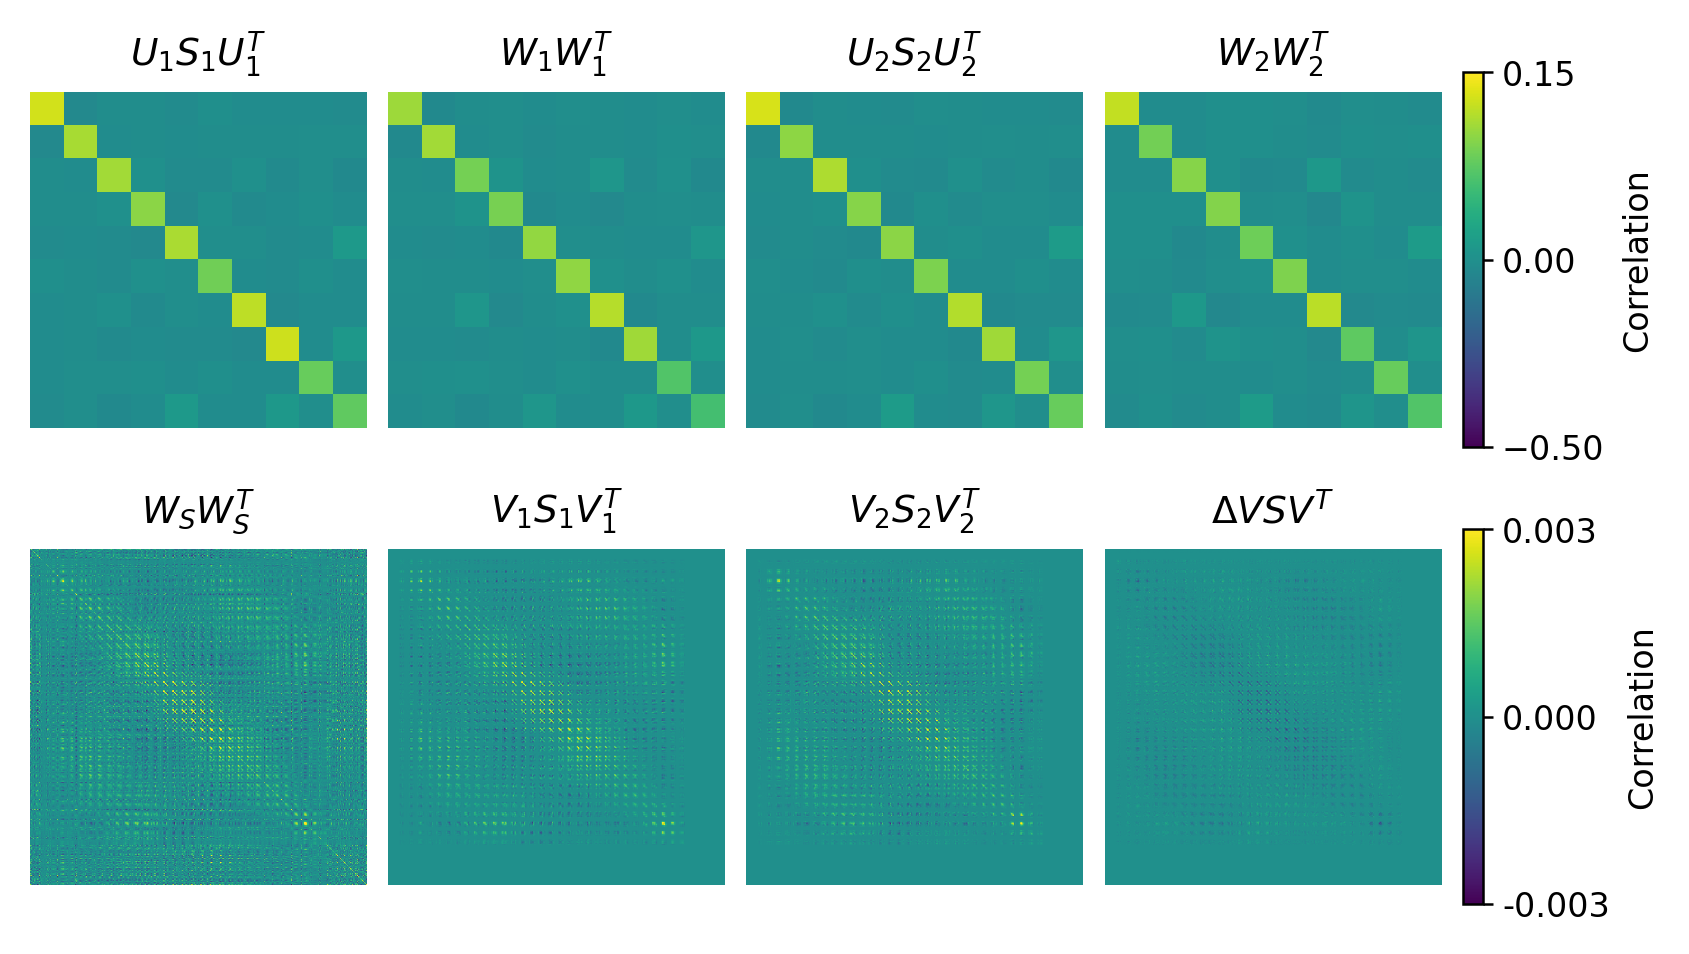

In [138]:
# ---------- print-friendly style ----------
mpl.rcParams.update({
    "figure.dpi": 300, "savefig.dpi": 300,
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "axes.linewidth": 0.6
})

# ---------- data / scales ----------
# top row (correlations): 0..vmax, sequential cmap
vmax = 0.15
cmap_top = mpl.colormaps["viridis"]
norm_top  = mpl.colors.TwoSlopeNorm(vmin=-0.5, vcenter=0,vmax=vmax)

# bottom row (deltas): symmetric ±dmax, diverging cmap
delta = VxiSVxi - V1SV1- V2SV2
dmax = 0.003#float(np.nanmax(np.abs(delta)))
Delta = VxiSVxi - V1SV1 - V2SV2
dlim = float(np.max(np.abs(Delta)))
cmap_bot  = cmap_bot = mpl.colormaps["viridis"]
norm_bot  = mpl.colors.TwoSlopeNorm(vmin=-dmax, vcenter=0, vmax=dmax)

top_panels = [
    (M1,   r"$U_1 S_1 U_1^{ T}$"),
    (W1W1, r"$W_1 W_1^{ T}$"),
    (M2,   r"$U_2 S_2 U_2^{ T}$"),
    (W2W2, r"$W_2 W_2^{ T}$"),
]
bot_panels = [
    (WSWS,   r"$W_S W_S^{ T}$"),
    (V1SV1,  r"$V_1 S_1 V_1^{ T}$"),
    (V2SV2,  r"$V_2 S_2 V_2^{ T}$"),
    (delta,  r"$\Delta VSV^{T}$"),
]

# ---------- layout ----------
fig = plt.figure(figsize=(10/1.6, 3.6), constrained_layout=False)
gs  = gridspec.GridSpec(nrows=2, ncols=5, width_ratios=[1,1,1,1,0.06],
                        height_ratios=[1,1], wspace=0.08, hspace=0.22, figure=fig)

axes_top = [fig.add_subplot(gs[0, j]) for j in range(4)]
axes_bot = [fig.add_subplot(gs[1, j]) for j in range(4)]

# ---------- draw ----------
letters = iter(string.ascii_uppercase)

label=[ "(a)", "(b)", "(c)", "(d)","(e)", "(f)", "(c)", "(d)"]
for j, (A, title) in enumerate(top_panels):
    ax = axes_top[j]
    A  = np.asarray(A)
    im = ax.imshow(A, cmap=cmap_top, norm=norm_top, interpolation="nearest", rasterized=True)
    #annotate_diagonal(ax, A, cmap=cmap_top, norm=norm_top)
    ax.set_title(title, pad=6)
    hide_axes(ax)
   #add_panel_label(ax, label[j])

label=["(e)", "(f)", "(g)", "(h)", "(a)", "(b)", "(c)", "(d)"]
for j, (B, title) in enumerate(bot_panels):
    ax = axes_bot[j]
    B  = np.asarray(B)
    im = ax.imshow(B, cmap=cmap_bot, norm=norm_bot, interpolation="nearest", rasterized=True)
    # usually no diagonal numbers here (often large); enable if you want:
    # annotate_diagonal(ax, B, cmap=cmap_bot, norm=norm_bot)
    ax.set_title(title, pad=6)
    hide_axes(ax)
    #add_panel_label(ax, label[j])

# ---------- colorbars (one per row) ----------
cax1 = fig.add_subplot(gs[0, -1])
cax2 = fig.add_subplot(gs[1, -1])

cb1 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_top,  cmap=cmap_top), cax=cax1)
cb1.set_label("Correlation", fontsize=8)
cb1.set_ticks([0, -0.5, vmax])

cb2 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_bot, cmap=cmap_bot), cax=cax2)
cb2.set_label(r"Correlation", fontsize=8)
cb2.set_ticks([-dmax, 0, dmax])
cb2.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))

for cb in (cb1, cb2):
    cb.ax.tick_params(length=2.5, width=0.6, pad=2)
    cb.outline.set_linewidth(0.6)

# Optional: save
fig.savefig("figure_vsv_conference_APPENDIX_BASE.pdf", bbox_inches="tight")
# fig.savefig("figure_vsv_conference.png", bbox_inches="tight")

plt.show()


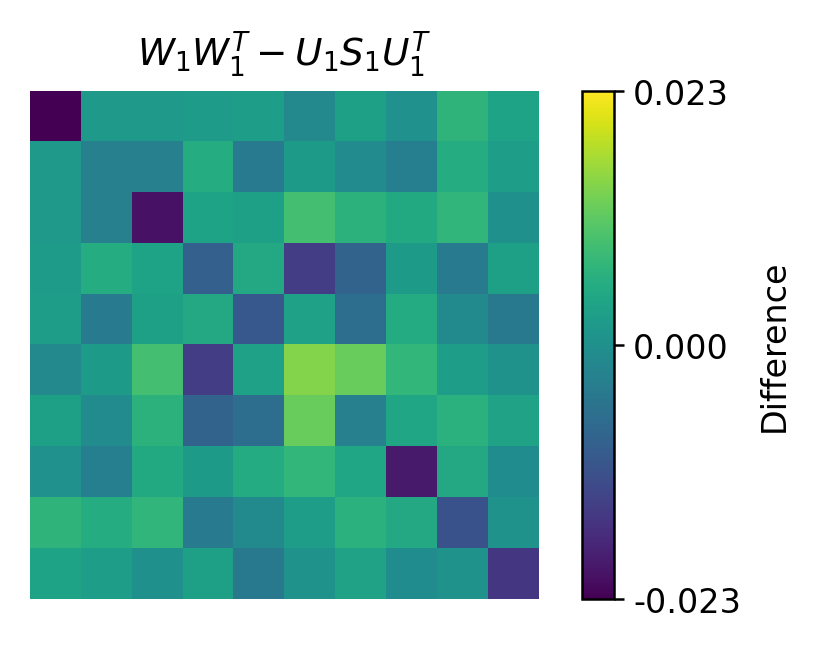

In [139]:
delta_w1 = W1W1 - M1

dmax = float(np.max(np.abs(delta_w1)))
if dmax == 0:
    dmax = 1e-12

cmap = mpl.colormaps["viridis"]
norm = mpl.colors.TwoSlopeNorm(vmin=-dmax, vcenter=0, vmax=dmax)

# ---------- layout ----------
fig = plt.figure(figsize=(2.6, 2.2), constrained_layout=False)
gs = gridspec.GridSpec(
    nrows=1, ncols=2,
    width_ratios=[1, 0.06],
    wspace=0.08,
    figure=fig
)

ax = fig.add_subplot(gs[0, 0])

# ---------- draw ----------
im = ax.imshow(
    np.asarray(delta_w1),
    cmap=cmap,
    norm=norm,
    interpolation="nearest",
    rasterized=True
)
ax.set_title(r"$W_1 W_1^{T} - U_1 S_1 U_1^{T}$", pad=6)
hide_axes(ax)

# ---------- colorbar ----------
cax = fig.add_subplot(gs[0, 1])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
cb.set_label("Difference", fontsize=8)
cb.set_ticks([-dmax, 0, dmax])
cb.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))
cb.ax.tick_params(length=2.5, width=0.6, pad=2)
cb.outline.set_linewidth(0.6)

fig.savefig("figure_W1W1_minus_U1S1U1.pdf", bbox_inches="tight")

Measuring Alignment

In [140]:
U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
O=V1@V2.T
UO, SO, VTO=np.linalg.svd(O, full_matrices=False)
print(SO)

[0.99999992 0.92984105 0.90920022 0.89635647 0.86774128 0.83403721
 0.77451166 0.73822673 0.66718437 0.51001074]


### Permuted Multi-MNIST

In [ ]:
qq=np.load("") #root QQ_NN_Perm50K50KepNS20_MTL_seed33.npy
Sigma_1o=np.loadtxt("") # root Sigma_1o_Perm50K200Kep.txt
Sigma_2o=np.loadtxt("") # root Sigma_2o_Perm50K200Kep.txt


In [147]:

WSWS=qq[0][:1296,:1296]
W1W1=qq[0][1296:1296+10, 1296:1296+10]
W2W2=qq[0][1296+10: 1296+20, 1296+10: 1296+20]
STL=False
Task1=False
if STL==False:
  U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
  U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
elif Task1:
  U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
  Sigma_2o=Sigma_1o
  U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
else:
  U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
  Sigma_1o=Sigma_2o
  U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
# assume U1,S1,Vt1; U2,S2,Vt2; U_xi,S_xi,Vt_xi are computed
XI=np.concatenate((Sigma_1o, Sigma_2o), axis=0)
U_xi,S_xi,Vt_xi=np.linalg.svd(XI,full_matrices=True)
m1 = U1.shape[0]
m2 = U2.shape[0]
r  = S_xi.size

# build original energy‐matrices
M1 = U1  @ np.diag(S1)  @ U1.T
M2 = U2  @ np.diag(S2)  @ U2.T
Mxi1= (U_xi@ np.diag(S_xi)@U_xi.T)[:m1, :m1]
Mxi2=(U_xi@ np.diag(S_xi)@U_xi.T)[m1:m1+m2, m1:m1+m2]
Mxi=(U_xi@ np.diag(S_xi)@U_xi.T)
# split pooled U_xi
U1_xi = U_xi[:m1, :m1]   # (m1 x r)
U2_xi = U_xi[m1:, m1:]   # (m2 x r)
# project into shared r‐dim space
M1p = U1_xi.T @ M1  @ U1_xi  # (r x r)
M2p =U2_xi.T @ M2  @ U2_xi  # (r x r)
Mxp = S_xi**2    # = diag(S_xi^2)


S1_mat = np.diag(S1)
S2_mat = np.diag(S2)
Sxi_mat = np.diag(S_xi)

# Third row: VSV^T
V1SV1 = V1.T @ np.diag(S1) @ V1
V2SV2 = V2.T @ np.diag(S2) @ V2
VxiSVxi = Vt_xi.T[:, :len(S_xi)] @ np.diag(S_xi) @ Vt_xi[:len(S_xi),:]

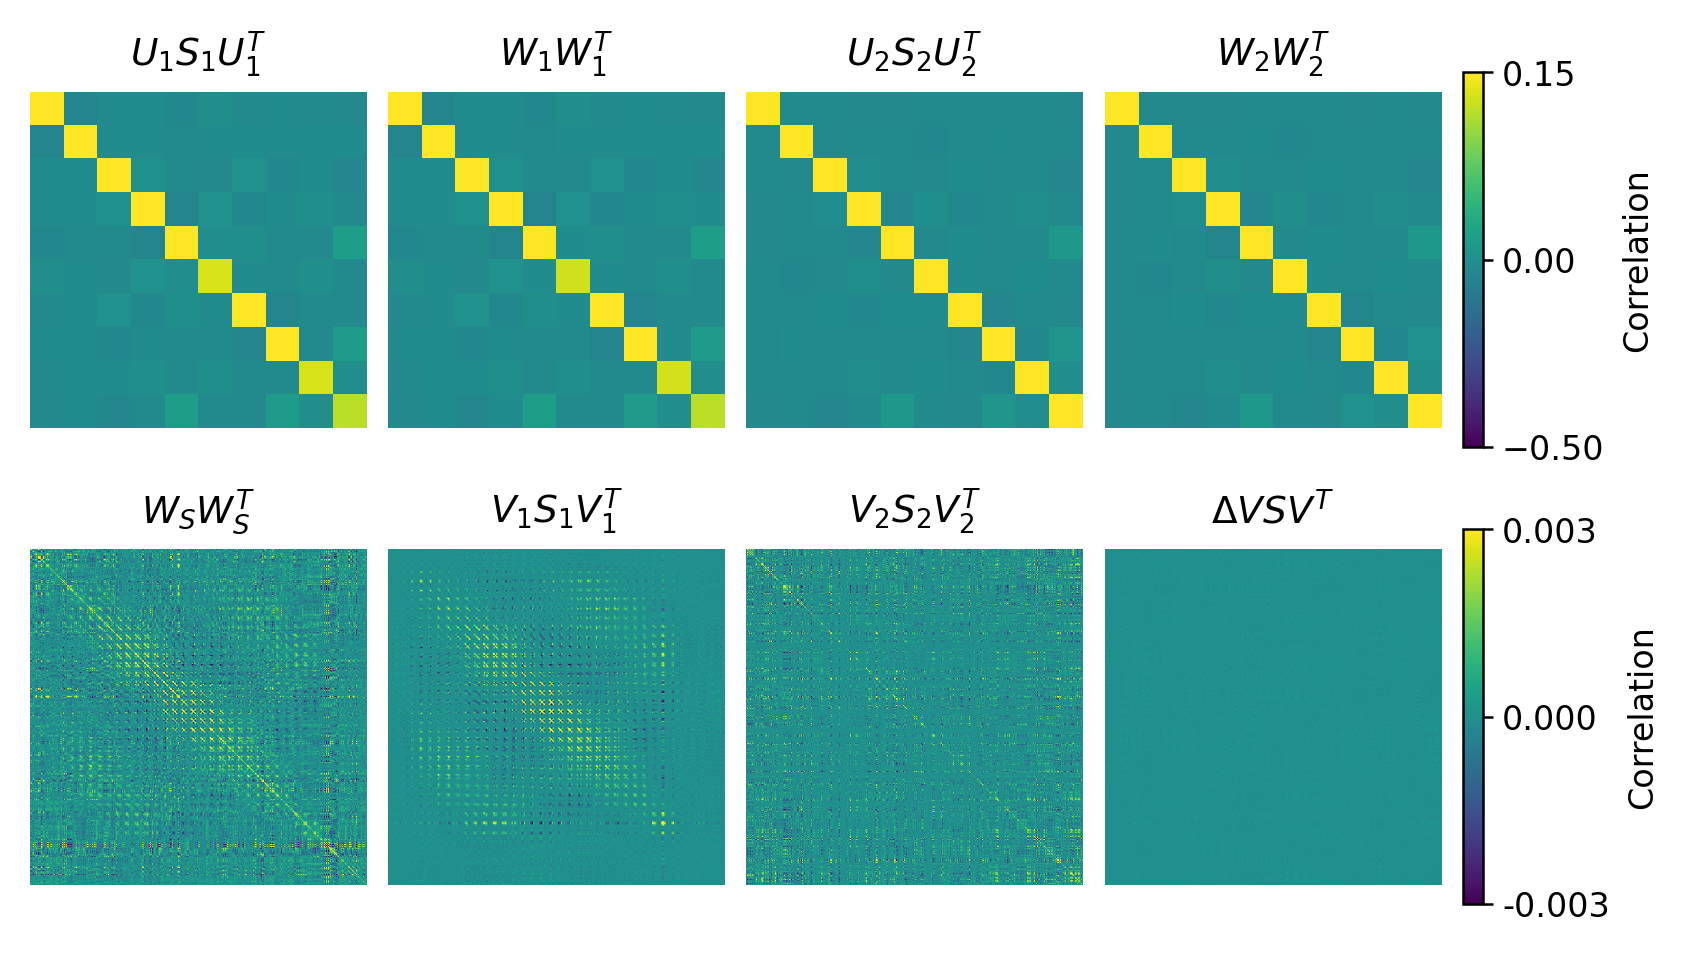

In [164]:

# ---------- print-friendly style ----------
mpl.rcParams.update({
    "figure.dpi": 300, "savefig.dpi": 300,
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "axes.linewidth": 0.6
})


# ---------- data / scales ----------
# top row (correlations): 0..vmax, sequential cmap
vmax = 0.15
cmap_top  = cmap_top = mpl.colormaps["viridis"]
norm_top  = mpl.colors.TwoSlopeNorm(vmin=-0.5, vcenter=0,vmax=vmax)

# bottom row (deltas): symmetric ±dmax, diverging cmap
delta = VxiSVxi - V1SV1- V2SV2
dmax = 0.003#float(np.nanmax(np.abs(delta)))
Delta = VxiSVxi - V1SV1 - V2SV2
dlim = float(np.max(np.abs(Delta)))
cmap_bot  = cmap_top = mpl.colormaps["viridis"]
norm_bot  = mpl.colors.TwoSlopeNorm(vmin=-dmax, vcenter=0, vmax=dmax)

top_panels = [
    (M1,   r"$U_1 S_1 U_1^{ T}$"),
    (W1W1, r"$W_1 W_1^{ T}$"),
    (M2,   r"$U_2 S_2 U_2^{ T}$"),
    (W2W2, r"$W_2 W_2^{ T}$"),
]
bot_panels = [
    (WSWS,   r"$W_S W_S^{ T}$"),
    (V1SV1,  r"$V_1 S_1 V_1^{ T}$"),
    (V2SV2,  r"$V_2 S_2 V_2^{ T}$"),
    (delta,  r"$\Delta VSV^{T}$"),
]

# ---------- layout ----------
fig = plt.figure(figsize=(10/1.6, 3.6), constrained_layout=False)
gs  = gridspec.GridSpec(nrows=2, ncols=5, width_ratios=[1,1,1,1,0.06],
                        height_ratios=[1,1], wspace=0.08, hspace=0.22, figure=fig)

axes_top = [fig.add_subplot(gs[0, j]) for j in range(4)]
axes_bot = [fig.add_subplot(gs[1, j]) for j in range(4)]

# ---------- draw ----------
letters = iter(string.ascii_uppercase)

label=[ "(a)", "(b)", "(c)", "(d)","(e)", "(f)", "(c)", "(d)"]
for j, (A, title) in enumerate(top_panels):
    ax = axes_top[j]
    A  = np.asarray(A)
    im = ax.imshow(A, cmap=cmap_top, norm=norm_top, interpolation="nearest", rasterized=True)
    #annotate_diagonal(ax, A, cmap=cmap_top, norm=norm_top)
    ax.set_title(title, pad=6)
    hide_axes(ax)
   #add_panel_label(ax, label[j])

label=["(e)", "(f)", "(g)", "(h)", "(a)", "(b)", "(c)", "(d)"]
for j, (B, title) in enumerate(bot_panels):
    ax = axes_bot[j]
    B  = np.asarray(B)
    im = ax.imshow(B, cmap=cmap_bot, norm=norm_bot, interpolation="nearest", rasterized=True)
    # usually no diagonal numbers here (often large); enable if you want:
    # annotate_diagonal(ax, B, cmap=cmap_bot, norm=norm_bot)
    ax.set_title(title, pad=6)
    hide_axes(ax)
    #add_panel_label(ax, label[j])

# ---------- colorbars (one per row) ----------
cax1 = fig.add_subplot(gs[0, -1])
cax2 = fig.add_subplot(gs[1, -1])

cb1 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_top,  cmap=cmap_top), cax=cax1)
cb1.set_label("Correlation", fontsize=8)
cb1.set_ticks([0, -0.5, vmax])

cb2 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_bot, cmap=cmap_bot), cax=cax2)
cb2.set_label(r"Correlation", fontsize=8)
cb2.set_ticks([-dmax, 0, dmax])
cb2.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))

for cb in (cb1, cb2):
    cb.ax.tick_params(length=2.5, width=0.6, pad=2)
    cb.outline.set_linewidth(0.6)

# Optional: save
fig.savefig("figure_vsv_conference_APPENDIX_BASE.pdf", bbox_inches="tight")
# fig.savefig("figure_vsv_conference.png", bbox_inches="tight")

plt.show()


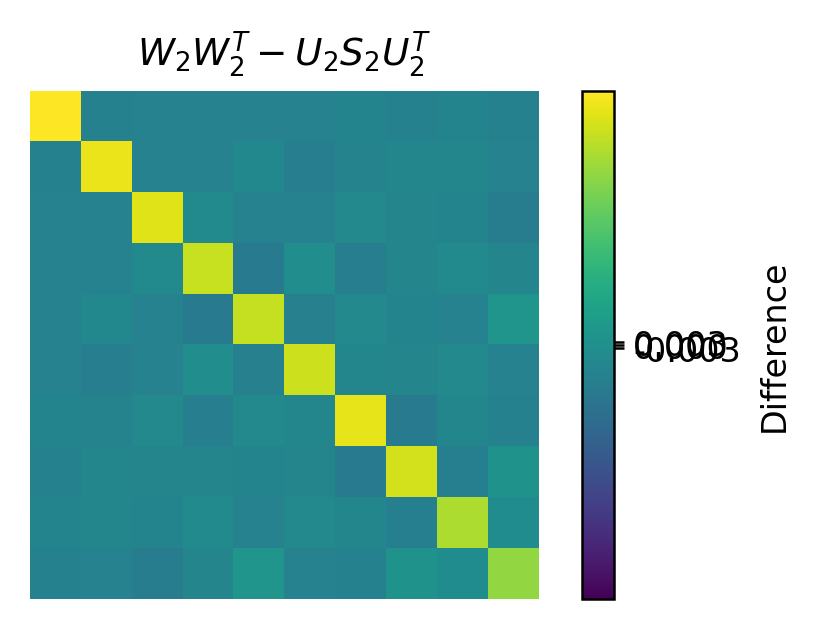

In [158]:
delta_w1 = W1W1 - M1
delta_w2 = W2W2
dmax = float(np.max(np.abs(delta_w1)))
if dmax == 0:
    dmax = 1e-12

cmap = mpl.colormaps["viridis"]
norm = mpl.colors.TwoSlopeNorm(vmin=-0.238, vcenter=0, vmax=0.238)

# ---------- layout ----------
fig = plt.figure(figsize=(2.6, 2.2), constrained_layout=False)
gs = gridspec.GridSpec(
    nrows=1, ncols=2,
    width_ratios=[1, 0.06],
    wspace=0.08,
    figure=fig
)

ax = fig.add_subplot(gs[0, 0])

# ---------- draw ----------
im = ax.imshow(
    np.asarray(delta_w2),
    cmap=cmap,
    norm=norm,
    interpolation="nearest",
    rasterized=True
)
ax.set_title(r"$W_2 W_2^{T} - U_2 S_2 U_2^{T}$", pad=6)
hide_axes(ax)

# ---------- colorbar ----------
cax = fig.add_subplot(gs[0, 1])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
cb.set_label("Difference", fontsize=8)
cb.set_ticks([-dmax, 0, dmax])
cb.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))
cb.ax.tick_params(length=2.5, width=0.6, pad=2)
cb.outline.set_linewidth(0.6)

fig.savefig("figure_W1W1_minus_U1S1U1.pdf", bbox_inches="tight")
plt.show()

Measuring Alignment

In [150]:
U1, S1, V1=np.linalg.svd(Sigma_1o, full_matrices=False)
U2, S2, V2=np.linalg.svd(Sigma_2o, full_matrices=False)
O=V1@V2.T
UO, SO, VTO=np.linalg.svd(O, full_matrices=False)
print(SO)

[0.99999992 0.22489521 0.21616631 0.20345301 0.19097238 0.18109331
 0.17178741 0.15158802 0.14400653 0.13594876]


## Appendix 

In [ ]:
qq=np.load("") #root QQ_NN_BAS50K25KepNS20_MTL_seeds.npy
Sigma_1o=np.load("") # root Sigma_1o_BAS50K25KepNS20_MTL_seeds.npy
Sigma_2o=np.load("") # root Sigma_2o_BAS50K25KepNS20_MTL_seeds.npy

In [ ]:
def hide_axes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_aspect("equal")

# ---------- collect seedwise quantities ----------
USU_1_seed, USU_2_seed, USU_MTL_seed = [], [], []
VSV_1_seed, VSV_2_seed, VSV_MTL_seed = [], [], []
W1W1_seed, W2W2_seed, WSWS_seed = [], [], []
DW1_seed, DW2_seed = [], []
n_seeds = 20
STL = False
Task1 = False

for s in range(n_seeds):
    Sigma1 = Sigma_1o[s]
    Sigma2 = Sigma_2o[s]
    qq_s = qq[s]

    if torch.is_tensor(Sigma1):
        Sigma1 = Sigma1.detach().cpu().numpy()
    else:
        Sigma1 = np.asarray(Sigma1)

    if torch.is_tensor(Sigma2):
        Sigma2 = Sigma2.detach().cpu().numpy()
    else:
        Sigma2 = np.asarray(Sigma2)

    if torch.is_tensor(qq_s):
        qq_s = qq_s.detach().cpu().numpy()
    else:
        qq_s = np.asarray(qq_s)

    WSWS = qq_s[:1296, :1296]
    W1W1 = qq_s[1296:1296+10, 1296:1296+10]
    W2W2 = qq_s[1296+10:1296+20, 1296+10:1296+20]

    if STL is False:
        U1, S1, V1 = np.linalg.svd(Sigma1, full_matrices=False)
        U2, S2, V2 = np.linalg.svd(Sigma2, full_matrices=False)
    elif Task1:
        U1, S1, V1 = np.linalg.svd(Sigma1, full_matrices=False)
        Sigma2 = Sigma1
        U2, S2, V2 = np.linalg.svd(Sigma2, full_matrices=False)
    else:
        U2, S2, V2 = np.linalg.svd(Sigma2, full_matrices=False)
        Sigma1 = Sigma2
        U1, S1, V1 = np.linalg.svd(Sigma1, full_matrices=False)

    XI = np.concatenate((Sigma1, Sigma2), axis=0)
    U_xi, S_xi, Vt_xi = np.linalg.svd(XI, full_matrices=False)

    M1 = U1 @ np.diag(S1) @ U1.T
    M2 = U2 @ np.diag(S2) @ U2.T
    Mxi = U_xi @ np.diag(S_xi) @ U_xi.T

    V1SV1 = V1.T @ np.diag(S1) @ V1
    V2SV2 = V2.T @ np.diag(S2) @ V2
    VxiSVxi = Vt_xi.T @ np.diag(S_xi) @ Vt_xi

    USU_1_seed.append(M1)
    USU_2_seed.append(M2)
    USU_MTL_seed.append(Mxi)

    VSV_1_seed.append(V1SV1)
    VSV_2_seed.append(V2SV2)
    VSV_MTL_seed.append(VxiSVxi)

    W1W1_seed.append(W1W1)
    W2W2_seed.append(W2W2)
    WSWS_seed.append(WSWS)

    M1 = U1 @ np.diag(S1) @ U1.T
    M2 = U2 @ np.diag(S2) @ U2.T
    
    W1W1 = qq_s[1296:1296+10, 1296:1296+10]
    W2W2 = qq_s[1296+10:1296+20, 1296+10:1296+20]

    
    DW1_seed.append(W1W1 - M1)
    DW2_seed.append(W2W2 - M2)

# ---------- mean/std ----------
USU_1_mean, USU_1_std = np.mean(USU_1_seed, axis=0), np.std(USU_1_seed, axis=0)
USU_2_mean, USU_2_std = np.mean(USU_2_seed, axis=0), np.std(USU_2_seed, axis=0)
USU_MTL_mean, USU_MTL_std = np.mean(USU_MTL_seed, axis=0), np.std(USU_MTL_seed, axis=0)

VSV_1_mean, VSV_1_std = np.mean(VSV_1_seed, axis=0), np.std(VSV_1_seed, axis=0)
VSV_2_mean, VSV_2_std = np.mean(VSV_2_seed, axis=0), np.std(VSV_2_seed, axis=0)
VSV_MTL_mean, VSV_MTL_std = np.mean(VSV_MTL_seed, axis=0), np.std(VSV_MTL_seed, axis=0)

W1W1_mean, W1W1_std = np.mean(W1W1_seed, axis=0), np.std(W1W1_seed, axis=0)
W2W2_mean, W2W2_std = np.mean(W2W2_seed, axis=0), np.std(W2W2_seed, axis=0)
WSWS_mean, WSWS_std = np.mean(WSWS_seed, axis=0), np.std(WSWS_seed, axis=0)

VSV_delta_mean = VSV_MTL_mean - VSV_1_mean - VSV_2_mean
VSV_delta_std = np.std(np.asarray(VSV_MTL_seed) - np.asarray(VSV_1_seed) - np.asarray(VSV_2_seed), axis=0)
DW1_mean = np.mean(np.asarray(DW1_seed), axis=0)
DW1_std  = np.std(np.asarray(DW1_seed), axis=0)

DW2_mean = np.mean(np.asarray(DW2_seed), axis=0)
DW2_std  = np.std(np.asarray(DW2_seed), axis=0)
# ---------- choose figure content ----------
top_panels = [
    (USU_1_mean, r"$\mathbb{E}[U_1 S_1 U_1^{T}]$"),
    (W1W1_mean,  r"$\mathbb{E}[W_1 W_1^{T}]$"),
    (USU_2_mean, r"$\mathbb{E}[U_2 S_2 U_2^{T}]$"),
    (W2W2_mean,  r"$\mathbb{E}[W_2 W_2^{T}]$"),
]

mid_panels = [
    (WSWS_mean,      r"$\mathbb{E}[W_S W_S^{T}]$"),
    (VSV_1_mean,     r"$\mathbb{E}[V_1 S_1 V_1^{T}]$"),
    (VSV_2_mean,     r"$\mathbb{E}[V_2 S_2 V_2^{T}]$"),
    (VSV_delta_mean, r"$\mathbb{E}[\Delta VSV^T]$"),
]

bot_panels = [
    (USU_1_std,   r"$\mathrm{std}(U_1 S_1 U_1^{T})$"),
    (USU_2_std,   r"$\mathrm{std}(U_2 S_2 U_2^{T})$"),
    (VSV_1_std,   r"$\mathrm{std}(V_1 S_1 V_1^{T})$"),
    (VSV_delta_std, r"$\mathrm{std}(\Delta VSV^T)$"),
]

# ---------- scales ----------
top_abs = max(float(np.nanmax(np.abs(A))) for A, _ in top_panels)
mid_abs = max(float(np.nanmax(np.abs(A))) for A, _ in mid_panels)
bot_max = max(float(np.nanmax(A)) for A, _ in bot_panels)

if top_abs == 0: top_abs = 1e-12
if mid_abs == 0: mid_abs = 1e-12
if bot_max == 0: bot_max = 1e-12

cmap_mean = mpl.cm.get_cmap("viridis")
cmap_std = mpl.cm.get_cmap("viridis")

norm_top = mpl.colors.TwoSlopeNorm(vmin=-top_abs, vcenter=0, vmax=top_abs)
norm_mid = mpl.colors.TwoSlopeNorm(vmin=-mid_abs, vcenter=0, vmax=mid_abs)
norm_bot = mpl.colors.Normalize(vmin=0, vmax=bot_max)

# ---------- layout ----------
fig = plt.figure(figsize=(10/1.6, 5.4), constrained_layout=False)
gs = gridspec.GridSpec(
    nrows=3, ncols=5,
    width_ratios=[1, 1, 1, 1, 0.06],
    height_ratios=[1, 1, 1],
    wspace=0.08, hspace=0.22,
    figure=fig
)

axes_top = [fig.add_subplot(gs[0, j]) for j in range(4)]
axes_mid = [fig.add_subplot(gs[1, j]) for j in range(4)]
axes_bot = [fig.add_subplot(gs[2, j]) for j in range(4)]

# ---------- draw ----------
for j, (A, title) in enumerate(top_panels):
    ax = axes_top[j]
    ax.imshow(np.asarray(A), cmap=cmap_mean, norm=norm_top, interpolation="nearest", rasterized=True)
    ax.set_title(title, pad=6)
    hide_axes(ax)

for j, (A, title) in enumerate(mid_panels):
    ax = axes_mid[j]
    ax.imshow(np.asarray(A), cmap=cmap_mean, norm=norm_mid, interpolation="nearest", rasterized=True)
    ax.set_title(title, pad=6)
    hide_axes(ax)

for j, (A, title) in enumerate(bot_panels):
    ax = axes_bot[j]
    ax.imshow(np.asarray(A), cmap=cmap_std, norm=norm_bot, interpolation="nearest", rasterized=True)
    ax.set_title(title, pad=6)
    hide_axes(ax)

# ---------- colorbars ----------
cax1 = fig.add_subplot(gs[0, -1])
cax2 = fig.add_subplot(gs[1, -1])
cax3 = fig.add_subplot(gs[2, -1])

cb1 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_top, cmap=cmap_mean), cax=cax1)
cb1.set_label("Mean", fontsize=8)
cb1.set_ticks([-top_abs, 0, top_abs])
cb1.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))

cb2 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_mid, cmap=cmap_mean), cax=cax2)
cb2.set_label("Mean", fontsize=8)
cb2.set_ticks([-mid_abs, 0, mid_abs])
cb2.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))

cb3 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_bot, cmap=cmap_std), cax=cax3)
cb3.set_label("Std", fontsize=8)
cb3.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3e'))

for cb in (cb1, cb2, cb3):
    cb.ax.tick_params(length=2.5, width=0.6, pad=2)
    cb.outline.set_linewidth(0.6)

fig.savefig("figure_mean_std_seedwise.pdf", bbox_inches="tight")
plt.show()